Install and Imports

In [1]:
!pip install lightly --quiet

import os, json, time, math, random, copy
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt

# EMA / momentum utilities (same lightly helpers used in the BYOL notebook)
from lightly.models.utils import deactivate_requires_grad, update_momentum

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("torch:", torch.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.2/891.2 kB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.8/155.8 kB 11.7 MB/s eta 0:00:00
Device: cuda
torch: 2.10.0+cu128


Load Part A split

In [2]:
SPLIT_PATH = "/kaggle/input/notebooks/yeamins/438-assignment-a/split.json"
DATA_ROOT  = "/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/Ar-PlaqSegm1 First Argentine database of B-mode ul"

with open(SPLIT_PATH) as f:
    split = json.load(f)

def fix_paths(records, new_root):
    fixed = []
    for rec in records:
        r = rec.copy()
        for key in ["img_path", "mask_path"]:
            parts = r[key].replace("\\", "/").split("/")
            r[key] = os.path.join(new_root, parts[-2], parts[-1])
        fixed.append(r)
    return fixed

train_records = fix_paths(split["train"], DATA_ROOT)   # unlabeled pretraining — used in THIS notebook
val_records   = fix_paths(split["val"],   DATA_ROOT)   # labeled fine-tuning  — used in the downstream notebook
test_records  = fix_paths(split["test"],  DATA_ROOT)   # monitoring + final eval — used in the downstream notebook
MASK_THRESHOLD = split["mask_threshold"]

print(f"Train (unlabeled): {len(train_records)}")
print(f"Val (labeled):     {len(val_records)}")
print(f"Test (eval):       {len(test_records)}")

Train (unlabeled): 416
Val (labeled):     73
Test (eval):       48


Multi-Crop Dataset

In [3]:
class MultiCropTransform:
    def __init__(self, global_size=224, local_size=98, n_local_crops=4):
        normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        self.global_crop = T.Compose([
            T.RandomResizedCrop(global_size, scale=(0.4, 1.0), interpolation=T.InterpolationMode.BICUBIC),
            T.RandomHorizontalFlip(),
            T.ToTensor(),
            normalize,
        ])
        self.local_crop = T.Compose([
            T.RandomResizedCrop(local_size, scale=(0.05, 0.4), interpolation=T.InterpolationMode.BICUBIC),
            T.RandomHorizontalFlip(),
            T.ToTensor(),
            normalize,
        ])
        self.n_local_crops = n_local_crops

    def __call__(self, img):
        crops = [self.global_crop(img), self.global_crop(img)]           # 2 global views
        crops += [self.local_crop(img) for _ in range(self.n_local_crops)]  # N local views
        return crops


class DINOPretrainDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        img = cv2.imread(self.records[idx]["img_path"], cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        img = Image.fromarray(img)
        return self.transform(img)   # list of crop tensors (different resolutions)


def multicrop_collate(batch):
    n_crops = len(batch[0])
    return [torch.stack([sample[i] for sample in batch]) for i in range(n_crops)]

N_LOCAL_CROPS = 4
dino_transform = MultiCropTransform(global_size=224, local_size=98, n_local_crops=N_LOCAL_CROPS)

pretrain_ds = DINOPretrainDataset(train_records, dino_transform)
pretrain_loader = DataLoader(
    pretrain_ds, batch_size=32, shuffle=True,
    num_workers=2, drop_last=True, pin_memory=True,
    collate_fn=multicrop_collate
)
print(f"Pretrain batches per epoch: {len(pretrain_loader)}")
print(f"Crops per image: 2 global + {N_LOCAL_CROPS} local = {2 + N_LOCAL_CROPS}")

Pretrain batches per epoch: 13
Crops per image: 2 global + 4 local = 6


Sanity Check

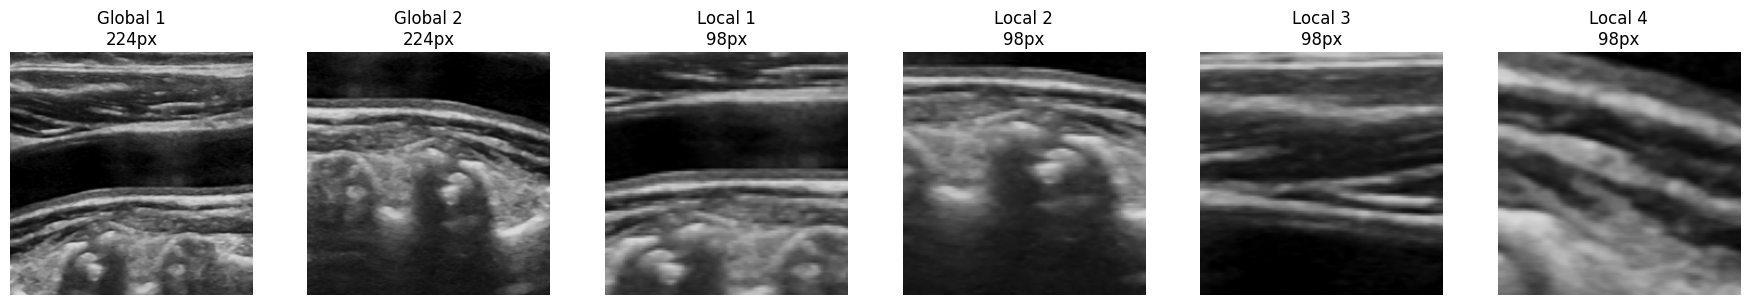

In [4]:
def denorm(t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (t * std + mean).clamp(0,1).permute(1,2,0).numpy()

sample_crops = pretrain_ds[0]   # list: [global1, global2, local1..local4]
fig, axes = plt.subplots(1, len(sample_crops), figsize=(3*len(sample_crops), 3))
labels = ["Global 1", "Global 2"] + [f"Local {i+1}" for i in range(N_LOCAL_CROPS)]
for i, (crop, label) in enumerate(zip(sample_crops, labels)):
    axes[i].imshow(denorm(crop)); axes[i].set_title(f"{label}\n{crop.shape[-1]}px"); axes[i].axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/dinov2_multicrop_sanity.png", dpi=150); plt.show()

DINOv2 model — ViT-S/14 backbone + projection head

In [5]:
class DINOHead(nn.Module):
    def __init__(self, in_dim, out_dim, hidden_dim=2048, bottleneck_dim=256, nlayers=3):
        super().__init__()
        layers = [nn.Linear(in_dim, hidden_dim), nn.GELU()]
        for _ in range(nlayers - 2):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.GELU()]
        layers += [nn.Linear(hidden_dim, bottleneck_dim)]
        self.mlp = nn.Sequential(*layers)
        self.last_layer = nn.utils.parametrizations.weight_norm(nn.Linear(bottleneck_dim, out_dim, bias=False))
        self.last_layer.parametrizations.weight.original0.data.fill_(1)
        self.last_layer.parametrizations.weight.original0.requires_grad = False

    def forward(self, x):
        x = self.mlp(x)
        x = F.normalize(x, dim=-1, p=2)
        return self.last_layer(x)


DINO_CHECKPOINT = "dinov2_vits14"   # ViT-S/14 — recommended size for Kaggle GPU memory (Sec 8)
OUT_DIM = 1024                       # prototype count — reduced from the ImageNet-scale 65536 given the small (~291 img) corpus

student_backbone = torch.hub.load("facebookresearch/dinov2", DINO_CHECKPOINT)
teacher_backbone = copy.deepcopy(student_backbone)
student_head = DINOHead(in_dim=student_backbone.embed_dim, out_dim=OUT_DIM)
teacher_head = copy.deepcopy(student_head)

student_backbone.to(device); teacher_backbone.to(device)
student_head.to(device);     teacher_head.to(device)

deactivate_requires_grad(teacher_backbone)
deactivate_requires_grad(teacher_head)

PATCH_SIZE = student_backbone.patch_size
HIDDEN_DIM = student_backbone.embed_dim
print(f"Backbone: {DINO_CHECKPOINT} | patch size: {PATCH_SIZE} | embed dim: {HIDDEN_DIM}")
print(f"Student params: {sum(p.numel() for p in student_backbone.parameters())/1e6:.1f}M (backbone) "
      f"+ {sum(p.numel() for p in student_head.parameters())/1e3:.0f}K (head)")


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 485MB/s]


Backbone: dinov2_vits14 | patch size: 14 | embed dim: 384
Student params: 22.1M (backbone) + 5773K (head)


DINO self-distillation loss

In [6]:
class DINOLoss(nn.Module):
    def __init__(self, out_dim, student_temp=0.1, teacher_temp=0.04, center_momentum=0.9):
        super().__init__()
        self.student_temp = student_temp
        self.teacher_temp = teacher_temp
        self.center_momentum = center_momentum
        self.register_buffer("center", torch.zeros(1, out_dim))

    def forward(self, student_out, teacher_out):
        # student_out: list of [B, out_dim] logits, one per crop (global + local)
        # teacher_out: list of [B, out_dim] logits, one per GLOBAL crop only
        student_logp = [F.log_softmax(s / self.student_temp, dim=-1) for s in student_out]
        teacher_p = [F.softmax((t - self.center) / self.teacher_temp, dim=-1).detach() for t in teacher_out]

        total_loss, n_terms = 0.0, 0
        for iq, q in enumerate(teacher_p):
            for iv, logp_v in enumerate(student_logp):
                if iv == iq:   # skip a view matching itself
                    continue
                total_loss += torch.sum(-q * logp_v, dim=-1).mean()
                n_terms += 1
        total_loss = total_loss / n_terms
        self.update_center(teacher_out)
        return total_loss

    @torch.no_grad()
    def update_center(self, teacher_out):
        batch_center = torch.cat(teacher_out).mean(dim=0, keepdim=True)
        self.center = self.center * self.center_momentum + batch_center * (1 - self.center_momentum)

Pretraining Loop

In [7]:
PRETRAIN_CONFIG = {
    "epochs": 50,
    "batch_size": 32,
    "lr": 5e-5,
    "weight_decay": 0.04,
    "student_temp": 0.1,
    "teacher_temp": 0.04,
    "ema_decay_base": 0.996,     # teacher momentum — same cosine-ramp schedule used for BYOL
    "ema_decay_final": 1.0,
    "n_global_crops": 2,
    "n_local_crops": N_LOCAL_CROPS,
    "out_dim": OUT_DIM,
    "optimizer": "AdamW",
    "checkpoint": DINO_CHECKPOINT,
}

dino_loss_fn = DINOLoss(
    out_dim=PRETRAIN_CONFIG["out_dim"],
    student_temp=PRETRAIN_CONFIG["student_temp"],
    teacher_temp=PRETRAIN_CONFIG["teacher_temp"],
).to(device)

optimizer = torch.optim.AdamW(
    list(student_backbone.parameters()) + list(student_head.parameters()),
    lr=PRETRAIN_CONFIG["lr"],
    weight_decay=PRETRAIN_CONFIG["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PRETRAIN_CONFIG["epochs"])

def ema_decay_at(epoch, total_epochs, base=0.996):
    return 1 - (1 - base) * (math.cos(math.pi * epoch / total_epochs) + 1) / 2

pretrain_losses = []
epoch_times = []
student_backbone.train(); student_head.train()

for epoch in range(PRETRAIN_CONFIG["epochs"]):
    t0 = time.time()
    epoch_loss = 0.0
    tau = ema_decay_at(epoch, PRETRAIN_CONFIG["epochs"], PRETRAIN_CONFIG["ema_decay_base"])

    for crops in pretrain_loader:
        crops = [c.to(device) for c in crops]
        n_global = PRETRAIN_CONFIG["n_global_crops"]

        # Student sees every crop; teacher only sees the global crops
        student_out = [student_head(student_backbone(c)) for c in crops]
        with torch.no_grad():
            teacher_out = [teacher_head(teacher_backbone(c)) for c in crops[:n_global]]

        loss = dino_loss_fn(student_out, teacher_out)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # EMA update — teacher moves slowly toward student
        update_momentum(student_backbone, teacher_backbone, m=tau)
        update_momentum(student_head, teacher_head, m=tau)

        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / len(pretrain_loader)
    dt = time.time() - t0
    pretrain_losses.append(avg_loss)
    epoch_times.append(dt)
    print(f"Epoch {epoch+1:02d}/50 | DINO loss: {avg_loss:.4f} | tau={tau:.4f} | {dt:.1f}s")

if max(epoch_times) > 600:
    print("NOTE: per-epoch pretrain time exceeded 10 min — this confirms the split into pretrain + downstream notebooks (Sec 3.2).")

# Save student backbone only — the projection head and teacher network are discarded after pretraining
torch.save(student_backbone.state_dict(), "/kaggle/working/dinov2_encoder.pt")

pretrain_meta = {
    "checkpoint": DINO_CHECKPOINT,
    "patch_size": PATCH_SIZE,
    "hidden_dim": HIDDEN_DIM,
    "n_global_crops": PRETRAIN_CONFIG["n_global_crops"],
    "n_local_crops": PRETRAIN_CONFIG["n_local_crops"],
    "out_dim": PRETRAIN_CONFIG["out_dim"],
    "ema_decay_base": PRETRAIN_CONFIG["ema_decay_base"],
    "epochs": PRETRAIN_CONFIG["epochs"],
    "epoch_times_sec": epoch_times,
    "pretrain_losses": pretrain_losses,
    "mean_epoch_sec": float(np.mean(epoch_times)),
    "total_min": float(sum(epoch_times)/60),
}
with open("/kaggle/working/dinov2_pretrain_meta.json", "w") as f:
    json.dump(pretrain_meta, f, indent=2)

print(f"\nMean epoch time: {np.mean(epoch_times):.1f}s")
print(f"Total pretrain time: {sum(epoch_times)/60:.1f} min")

Epoch 01/50 | DINO loss: 6.6374 | tau=0.9960 | 19.8s
Epoch 02/50 | DINO loss: 6.9213 | tau=0.9960 | 18.4s
Epoch 03/50 | DINO loss: 6.9791 | tau=0.9960 | 19.0s
Epoch 04/50 | DINO loss: 6.9545 | tau=0.9960 | 19.3s
Epoch 05/50 | DINO loss: 6.9368 | tau=0.9961 | 19.9s
Epoch 06/50 | DINO loss: 6.9286 | tau=0.9961 | 20.1s
Epoch 07/50 | DINO loss: 6.9260 | tau=0.9961 | 19.6s
Epoch 08/50 | DINO loss: 6.9259 | tau=0.9962 | 19.5s
Epoch 09/50 | DINO loss: 6.9266 | tau=0.9962 | 19.7s
Epoch 10/50 | DINO loss: 6.9274 | tau=0.9963 | 19.7s
Epoch 11/50 | DINO loss: 6.9282 | tau=0.9964 | 19.6s
Epoch 12/50 | DINO loss: 6.9288 | tau=0.9965 | 19.7s
Epoch 13/50 | DINO loss: 6.9294 | tau=0.9965 | 19.7s
Epoch 14/50 | DINO loss: 6.9298 | tau=0.9966 | 19.7s
Epoch 15/50 | DINO loss: 6.9301 | tau=0.9967 | 19.8s
Epoch 16/50 | DINO loss: 6.9303 | tau=0.9968 | 19.8s
Epoch 17/50 | DINO loss: 6.9305 | tau=0.9969 | 19.6s
Epoch 18/50 | DINO loss: 6.9306 | tau=0.9970 | 19.7s
Epoch 19/50 | DINO loss: 6.9307 | tau=0.9971 |

Plot Pretraining Loss

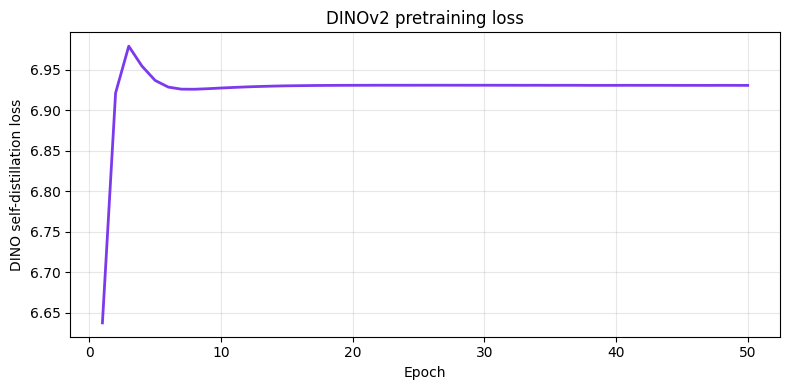

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, PRETRAIN_CONFIG["epochs"]+1), pretrain_losses, color="#7C3AED", linewidth=2)
ax.set_xlabel("Epoch"); ax.set_ylabel("DINO self-distillation loss")
ax.set_title("DINOv2 pretraining loss")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/dinov2_pretrain_loss.png", dpi=150)
plt.show()